In [ ]:
!pip install -U transformers
!pip install -q bitsandbytes accelerate transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 11.9 MB/s eta 0:00:00


In [ ]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

True
Tesla T4


In [ ]:
import librosa
import torch
import pandas as pd
import numpy as np
from pathlib import Path

import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, f1_score,confusion_matrix,accuracy_score,precision_score,recall_score
from sklearn.model_selection import train_test_split

In [ ]:
from transformers import AutoProcessor, Qwen2AudioForConditionalGeneration


## Local Inference on GPU
Model page: https://huggingface.co/Qwen/Qwen2.5-Omni-7B

⚠️ If the generated code snippets do not work, please open an issue on either the [model repo](https://huggingface.co/Qwen/Qwen2.5-Omni-7B)
			and/or on [huggingface.js](https://github.com/huggingface/huggingface.js/blob/main/packages/tasks/src/model-libraries-snippets.ts) 🙏

In [ ]:
import torch
from transformers import (
    AutoProcessor,
    Qwen2AudioForConditionalGeneration,
    BitsAndBytesConfig
)

MODEL_ID = "Qwen/Qwen2-Audio-7B-Instruct"

processor = AutoProcessor.from_pretrained(MODEL_ID)

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

model = Qwen2AudioForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto"
)

model.eval()

Loading weights:   0%|          | 0/876 [00:00<?, ?it/s]

Qwen2AudioForConditionalGeneration(
  (model): Qwen2AudioModel(
    (audio_tower): Qwen2AudioEncoder(
      (conv1): Conv1d(128, 1280, kernel_size=(3,), stride=(1,), padding=(1,))
      (conv2): Conv1d(1280, 1280, kernel_size=(3,), stride=(2,), padding=(1,))
      (embed_positions): Embedding(1500, 1280)
      (layers): ModuleList(
        (0-31): 32 x Qwen2AudioEncoderLayer(
          (self_attn): Qwen2AudioAttention(
            (k_proj): Linear4bit(in_features=1280, out_features=1280, bias=False)
            (v_proj): Linear4bit(in_features=1280, out_features=1280, bias=True)
            (q_proj): Linear4bit(in_features=1280, out_features=1280, bias=True)
            (out_proj): Linear4bit(in_features=1280, out_features=1280, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
          (activation_fn): GELUActivation()
          (fc1): Linear4bit(in_features=1280, out_features=5120, bias=True)
          (fc2): Linear4bit(i

In [ ]:
print(model.device)

cuda:0


In [ ]:
emotions = [
    "anger",
    "disgust",
    "fear",
    "happiness",
    "sadness"
]

In [ ]:
def predict_emotion(wav_path, emotions):
    # Qwen processor tells us which sampling rate it expects
    target_sr = processor.feature_extractor.sampling_rate

    audio, sr = librosa.load(
        wav_path,
        sr=target_sr,
        mono=True
    )

    emotion_string = ", ".join(emotions)

  reasoning_prompt = f"""
    Given the Content: {content}
    Emotion: {emotion}

    Provide a detailed reasoning that explains how the emotion and its intensity
    relate to the spoken content and the audio's characteristics, such as tone,
    pitch, speaking style, clarity, and other acoustic properties.

    ## Here are some rules you should follow:
    - DO NOT use the word "{emotion}" in your reasoning.
    - DO NOT use open-ended questions or follow-up invitations in the reasoning.
    - DO NOT use "Well, you know" or "Well" in the reasoning.
    """
    conversation = [
        {
            "role": "user",
            "content": [
                {
                    "type": "audio",
                    "audio_url": str(wav_path)
                },
                {
                    "type": "text",
                    "text": (
                        "Listen carefully to the speaker's vocal delivery. "
                        "Classify the emotion expressed in the speech, based primarily "
                        "on acoustic and prosodic cues such as tone, pitch, intensity, "
                        "rhythm and speaking style. "
                        f"Choose exactly one label from: {emotion_string}. "
                        "Return only the label."
                    )
                }
            ]
        }
    ]

    text = processor.apply_chat_template(
        conversation,
        add_generation_prompt=True,
        tokenize=False
    )

    inputs = processor(
        text=text,
        audio=[audio],
        return_tensors="pt",
        padding=True
    ).to(model.device)
    inputs = {
    k: v.to(model.device) if torch.is_tensor(v) else v
    for k, v in inputs.items()
    }

    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=10,
            do_sample=False
        )

    # Remove input/prompt tokens
    generated_ids = generated_ids[:, inputs["input_ids"].size(1):]

    response = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]

    return response.strip().lower()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
dataFile="/content/drive/MyDrive/data/dataset.csv"
data = pd.read_csv(dataFile,index_col = False,sep=",")

In [ ]:
data

,mfcc_1,mfcc_2,mfcc_3,mfcc_4,mfcc_5,mfcc_6,mfcc_7,mfcc_8,mfcc_9,mfcc_10,mfcc_11,mfcc_12,mfcc_13,emotion,filename
0,-299.98450,87.319020,-61.833230,-17.852484,-19.937574,-20.551935,-33.795400,-11.341667,-19.700586,-19.773966,-16.769290,-14.728676,-11.027959,anger,a19 (2).wav
1,-328.03912,91.234276,-17.556215,14.451467,-4.864509,-8.769917,-27.780870,-16.221110,-14.777812,-20.292595,-13.681153,-13.032110,-20.015177,happiness,h16 (1).wav
2,-280.33783,107.642820,-8.899505,21.771627,-1.722205,6.565788,-25.252258,0.152199,-18.340400,-26.169554,-3.375387,-8.557215,-8.042660,sadness,s15 (1).wav
3,-311.29360,103.162900,-41.687060,10.878167,-7.341278,-8.662815,-15.944193,7.825508,-5.374226,-20.204493,-6.672690,-2.041740,-7.759924,anger,a13 (5).wav
4,-256.67580,76.874300,-26.352484,40.261818,-16.789610,10.500903,-10.313868,-4.685866,-8.797047,-6.292166,-21.765003,-14.745240,-17.972761,disgust,d10 (4).wav
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
599,-357.21085,81.967020,-44.627700,14.213215,-9.680835,5.502525,-11.742521,-2.060557,-3.984080,-7.347529,-11.358060,-1.209170,-5.921447,anger,a12 (5).wav
600,-260.89560,95.877690,-29.986685,24.412191,-28.703512,6.064246,-26.227959,-12.482735,-9.571592,-8.065681,-24.339690,-6.449973,-13.472678,anger,a18 (4).wav
601,-279.62680,109.149086,-22.466711,16.629130,1.555209,0.627947,-29.468836,-0.961668,-17.335299,-25.600342,-16.997341,-11.349758,-9.137225,fear,f05 (5).wav
602,-260.48544,94.641060,-37.845310,6.646246,-32.899025,-5.108646,-36.413300,-9.082713,-15.220179,-31.384043,-24.881418,-11.855515,-18.991470,happiness,h13 (2).wav


In [ ]:
print(emotions)

['anger', 'disgust', 'fear', 'happiness', 'sadness']


In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [ ]:

import gc

dataset_path = Path(
    r"/content/drive/MyDrive/data/Acted Emotional Speech Dynamic Database"
)

X = []
y = []
filenames = []
bad_files = list()

for index, row in data.iterrows():
    emotion = row["emotion"]
    filename = row["filename"]
    wav_path = dataset_path / emotion / filename
    try:
        predicted_emotion = predict_emotion(wav_path, emotions)
        X.append(emotion)
        y.append(predicted_emotion) # Storing the predicted emotion
        filenames.append(wav_path.name)

    except Exception as e:
        print(f"Skipping: {wav_path}")
        print(f"Reason: {e}")
        bad_files.append(wav_path)


    gc.collect()
    torch.cuda.empty_cache()

[transformers] It is strongly recommended to pass the `sampling_rate` argument to `WhisperFeatureExtractor()`. Failing to do so can result in silent errors that might be hard to debug.
[transformers] It is strongly recommended to pass the `sampling_rate` argument to `WhisperFeatureExtractor()`. Failing to do so can result in silent errors that might be hard to debug.
[transformers] It is strongly recommended to pass the `sampling_rate` argument to `WhisperFeatureExtractor()`. Failing to do so can result in silent errors that might be hard to debug.
[transformers] It is strongly recommended to pass the `sampling_rate` argument to `WhisperFeatureExtractor()`. Failing to do so can result in silent errors that might be hard to debug.
[transformers] It is strongly recommended to pass the `sampling_rate` argument to `WhisperFeatureExtractor()`. Failing to do so can result in silent errors that might be hard to debug.
[transformers] It is strongly recommended to pass the `sampling_rate` argum

In [ ]:
print(X)

['anger', 'happiness', 'sadness', 'anger', 'disgust', 'fear', 'anger', 'happiness', 'anger', 'fear', 'anger', 'anger', 'anger', 'sadness', 'happiness', 'disgust', 'anger', 'disgust', 'disgust', 'anger', 'anger', 'happiness', 'sadness', 'sadness', 'happiness', 'fear', 'anger', 'disgust', 'sadness', 'happiness', 'sadness', 'disgust', 'anger', 'fear', 'disgust', 'happiness', 'disgust', 'sadness', 'happiness', 'fear', 'sadness', 'anger', 'sadness', 'sadness', 'anger', 'disgust', 'happiness', 'anger', 'anger', 'fear', 'fear', 'fear', 'anger', 'sadness', 'sadness', 'happiness', 'disgust', 'disgust', 'disgust', 'disgust', 'anger', 'disgust', 'sadness', 'sadness', 'sadness', 'anger', 'sadness', 'happiness', 'anger', 'happiness', 'fear', 'anger', 'happiness', 'happiness', 'happiness', 'sadness', 'sadness', 'disgust', 'sadness', 'fear', 'fear', 'happiness', 'happiness', 'happiness', 'anger', 'anger', 'disgust', 'disgust', 'sadness', 'disgust', 'disgust', 'sadness', 'anger', 'fear', 'fear', 'fear

In [ ]:
print(y)

['angry', 'fear', 'fear', 'angry', 'fear', 'fear', 'fear', 'fear', 'angry', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'angry', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'angry', 'sadness', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'angry', 'fear', 'fear', 'fear', 'fear', 'angry', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'sadness', 'sadness', 'fear', 'fear', 'angry', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'angry', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'sadness', 'fear', 'sadness', 'fear', 'fear', 'sadness', 'angry', 'fear', 'fear', 'fear', 'fear', 'angry', 'fear', 'angry', 'angry', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'laughter', 'fear', 'fear', 'fear', 'fear'

In [ ]:
print(filenames)

['a19 (2).wav', 'h16 (1).wav', 's15 (1).wav', 'a13 (5).wav', 'd10 (4).wav', 'f08 (1).wav', 'a02 (5).wav', 'h19 (4).wav', 'a13 (6).wav', 'f18 (6).wav', 'a10 (1).wav', 'a20 (4).wav', 'a19 (1).wav', 's19 (1).wav', 'h02 (3).wav', 'd19 (4).wav', 'a06 (1).wav', 'd15 (5).wav', 'd11 (1).wav', 'a15 (2).wav', 'a01 (3).wav', 'h02 (6).wav', 's10 (1).wav', 's20 (3).wav', 'h02 (2).wav', 'f13 (5).wav', 'a12 (6).wav', 'd03 (2).wav', 's13 (4).wav', 'h14 (4).wav', 's20 (2).wav', 'd07 (4).wav', 'a14 (4).wav', 'f03 (4).wav', 'd12 (3).wav', 'h16 (6).wav', 'd02 (5).wav', 's06 (5).wav', 'h14 (6).wav', 'f06 (4).wav', 's12 (5).wav', 'a05 (6).wav', 's05 (1).wav', 's16 (1).wav', 'a05 (1).wav', 'd10 (5).wav', 'h06 (3).wav', 'a18 (2).wav', 'a11 (3).wav', 'f20 (5).wav', 'f01 (3).wav', 'f01 (6).wav', 'a17 (5).wav', 's13 (3).wav', 's19 (4).wav', 'h10 (6).wav', 'd15 (2).wav', 'd07 (6).wav', 'd03 (4).wav', 'd12 (6).wav', 'a13 (4).wav', 'd09 (5).wav', 's20 (5).wav', 's10 (2).wav', 's02 (5).wav', 'a12 (4).wav', 's14 (3).

In [ ]:
print(model.hf_device_map)

In [ ]:
LABEL_MAPPING = {
    "angry": "anger",
    "anger": "anger",

    "happy": "happiness",
    "happiness": "happiness",

    "sad": "sadness",
    "sadness": "sadness",

    "fearful": "fear",
    "fear": "fear",

    "disgusted": "disgust",
    "disgust": "disgust",

    "neutral": "neutral"
}

In [ ]:
def normalize_prediction(prediction):

    prediction = prediction.strip().lower()

    if prediction in LABEL_MAPPING:
        return LABEL_MAPPING[prediction]

    return prediction
for i in range(len(y)):
    y[i] = normalize_prediction(y[i])


In [ ]:
print(y)

['anger', 'fear', 'fear', 'anger', 'fear', 'fear', 'fear', 'fear', 'anger', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'anger', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'anger', 'sadness', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'anger', 'fear', 'fear', 'fear', 'fear', 'anger', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'sadness', 'sadness', 'fear', 'fear', 'anger', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'anger', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'sadness', 'fear', 'sadness', 'fear', 'fear', 'sadness', 'anger', 'fear', 'fear', 'fear', 'fear', 'anger', 'fear', 'anger', 'anger', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'laughter', 'fear', 'fear', 'fear', 'fear'

In [ ]:
results = pd.DataFrame({
    "file": filenames,
    "true_emotion": X,
    "predicted_emotion": y
})

print(results.head())

          file true_emotion predicted_emotion
0  a19 (2).wav        anger             anger
1  h16 (1).wav    happiness              fear
2  s15 (1).wav      sadness              fear
3  a13 (5).wav        anger             anger
4  d10 (4).wav      disgust              fear


In [ ]:
def compute_metrics(df_test_y,y_test_true):
    # f1 score


    f1 = f1_score(y_test_true, df_test_y , average="macro", zero_division=0)
    print("F1 Score : " + str(f1))

    # precision

    precision=precision_score(y_test_true, df_test_y, average="macro", zero_division=0)
    print("Precision : " + str(precision))

    # recall


    recall=recall_score(y_test_true, df_test_y, average="macro", zero_division=0)
    print("Recall : " + str(recall))

    #accuracy

    accurancy=accuracy_score(y_test_true, df_test_y)
    print("Accuracy_score : " + str(accurancy))


    return  f1,  precision,  recall,  accurancy



In [ ]:
compute_metrics(results["true_emotion"],results["predicted_emotion"])

F1 Score : 0.22022887081544887
Precision : 0.2708406814832694
Recall : 0.4261551727420851
Accuracy_score : 0.32450331125827814


(0.22022887081544887,
 0.2708406814832694,
 0.4261551727420851,
 0.32450331125827814)

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        results["true_emotion"],
        results["predicted_emotion"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

       anger       0.73      0.40      0.52       121
     disgust       0.00      0.00      0.00       122
        fear       0.23      0.90      0.36       120
   happiness       1.00      0.02      0.03       119
    laughter       0.00      0.00      0.00         0
     sadness       0.60      0.30      0.40       122

    accuracy                           0.32       604
   macro avg       0.43      0.27      0.22       604
weighted avg       0.51      0.32      0.26       604



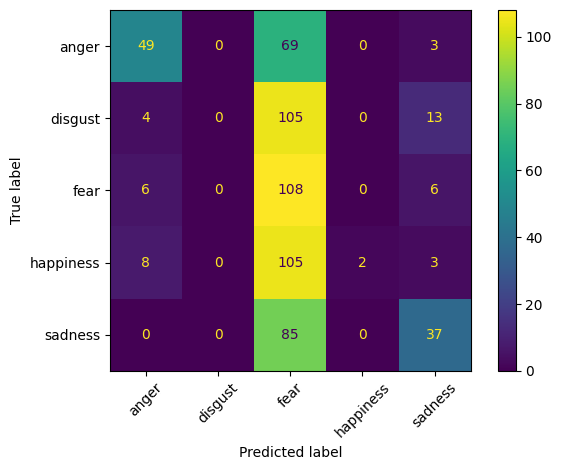

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = sorted(results["true_emotion"].unique())

cm = confusion_matrix(
    results["true_emotion"],
    results["predicted_emotion"],
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(xticks_rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
print(results["predicted_emotion"].value_counts())

predicted_emotion
fear         472
anger         67
sadness       62
happiness      2
laughter       1
Name: count, dtype: int64
